# Homework 1: Linear Regression

**Amirhossein Mahmoudi**

**Machine Learning · Dr. Ali Katanforosh**  
**MSc Computer Science · Shahid Beheshti University**

Predict daily bike rentals using Gaussian radial basis functions (RBFs) and
offline least squares. Study how both RBF width and number of centers affect
training and test RMSE.

**Run:** from the workspace root, run `uv sync --locked --group notebook`.
Open this notebook, select the workspace `.venv` Python kernel, and choose **Run All**.
Keep the extracted project folders together so the notebook can read the CSV.


In [1]:
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

%matplotlib inline

data_path = Path("data/raw/bike-sharing/day.csv")
if not data_path.exists():
    data_path = Path("../../data/raw/bike-sharing/day.csv")


## 1. Dataset description and provenance

Each observation is one day in Washington, D.C., from 2011-01-01 through
2012-12-31. The daily file contains **731 observations and 16 original columns**.
The target is a count of rentals rather than unique cyclists.

Capital Bikeshare produced the underlying operational trip logs. Hadi Fanaee-T
(LIAAD/University of Porto) prepared the research dataset by aggregating rental
activity and adding weather information from Freemeteo and calendar information.
The dataset supports demand prediction and event detection; it is observational
data, not a randomized experiment. The archive's original `Readme.txt` documents
this preparation. UCI currently lists the dataset under **CC BY 4.0**.

- [UCI dataset record](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset)
- Fanaee-T, H. (2013), *Bike Sharing*, [doi:10.24432/C5W894](https://doi.org/10.24432/C5W894).
- Fanaee-T and Gama (2013), *Event labeling combining ensemble detectors and
  background knowledge*, [doi:10.1007/s13748-013-0040-3](https://doi.org/10.1007/s13748-013-0040-3).

Downloaded on **2026-11-20** from the original UCI archive:
<https://archive.ics.uci.edu/static/public/275/bike%2Bsharing%2Bdataset.zip>.


### 1.1 Load the CSV and rename columns


In [2]:
def read_dataset(path):
    """Read the original CSV into a DataFrame without changing its values."""
    return pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")

df = read_dataset(data_path)


In [3]:
COLUMN_NAMES = {
    "instant": "record_id",
    "dteday": "date",
    "season": "season",
    "yr": "year",
    "mnth": "month",
    "holiday": "is_holiday",
    "weekday": "day_of_week",
    "workingday": "is_working_day",
    "weathersit": "weather_condition",
    "temp": "temperature",
    "atemp": "feels_like_temperature",
    "hum": "humidity",
    "windspeed": "wind_speed",
    "casual": "casual_rentals",
    "registered": "registered_rentals",
    "cnt": "total_rentals",
}

def rename_columns(data):
    """Use descriptive column names without changing the original data values."""
    return data.rename(columns=COLUMN_NAMES)

df = rename_columns(df)
display(df.head())


,record_id,date,season,year,month,is_holiday,day_of_week,is_working_day,weather_condition,temperature,feels_like_temperature,humidity,wind_speed,casual_rentals,registered_rentals,total_rentals
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.2,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.22927,0.436957,0.1869,82,1518,1600


### Feature dictionary and preprocessing decisions

| Column | Meaning | Treatment |
|---|---|---|
| `record_id` | Sequential record identifier | Excluded |
| `date` | Calendar date | Excluded; calendar indicators used instead |
| `season` | Season code, 1-4 | Four one-hot indicators |
| `year` | 0 = 2011, 1 = 2012 | Binary input |
| `month` | Month, 1-12 | Excluded to keep the seasonal representation compact |
| `is_holiday` | Holiday flag | Binary input |
| `day_of_week` | Weekday code, 0-6 | Seven one-hot indicators |
| `is_working_day` | Neither weekend nor holiday | Binary input |
| `weather_condition` | 1 clear; 2 mist/cloud; 3 light precipitation; 4 severe precipitation | Four one-hot indicators |
| `temperature` | Source-normalized temperature | Standardize on fitting data |
| `feels_like_temperature` | Source-normalized apparent temperature | Excluded because it overlaps temperature information |
| `humidity` | Relative humidity divided by 100 | Standardize on fitting data |
| `wind_speed` | Wind speed divided by 67 | Standardize on fitting data |
| `casual_rentals` | Casual-user rental count | Excluded: part of the target |
| `registered_rentals` | Registered-user rental count | Excluded: part of the target |
| `total_rentals` | Total daily rentals | Regression target, rentals/day |

The code checks `total_rentals = casual_rentals + registered_rentals` for every observation. Including
either component as a predictor would introduce target leakage.

Use temperature values as provided and treat season codes as categories.
Weather category 4 has no daily observations but stays in the fixed schema.

Three continuous variables, three binary variables, and 15 category indicators
produce **21 numeric inputs**. Indicators have a fixed source-defined category set.
No imputation, outlier removal, target transformation, or prediction clipping is used.


### 1.2 Choose the input columns

Exclude `total_rentals`, `casual_rentals`, and `registered_rentals` from the inputs to prevent target leakage.


In [4]:
CONTINUOUS = ("temperature", "humidity", "wind_speed")
BINARY = ("year", "is_holiday", "is_working_day")
CATEGORIES = {"season": (1, 2, 3, 4), "day_of_week": tuple(range(7)), "weather_condition": (1, 2, 3, 4)}


### 1.3 Check the data

Check missing values, category codes, and the identity `total_rentals = casual_rentals + registered_rentals`.


In [5]:
def validate_dataset(data):
    """Check for missing values, invalid category codes, and inconsistent counts."""
    if data.empty:
        raise ValueError("The dataset is empty")
    for column in data.columns:
        if any(not str(value).strip() for value in data[column]):
            raise ValueError(f"Missing values in {column}")
    for name in BINARY:
        if any(float(value) not in (0.0, 1.0) for value in data[name]):
            raise ValueError(f"Unexpected binary value in {name}")
    for name, levels in CATEGORIES.items():
        if any(float(value) not in levels for value in data[name]):
            raise ValueError(f"Unexpected category in {name}")
    # The two rental components must add up to the prediction target.
    for casual, registered, total in zip(data["casual_rentals"], data["registered_rentals"], data["total_rentals"]):
        if int(casual) + int(registered) != int(total):
            raise ValueError("Unexpected target-component mismatch")

validate_dataset(df)
print('Data checks passed.')


Data checks passed.


### 1.4 Prepare the numerical inputs


In [6]:
def numeric_features(data):
    """Return continuous/binary inputs as a numeric matrix and their column names.

    Each row is one day. These six columns are selected explicitly so neither
    the target nor its component counts can become model inputs.
    """
    names = list(CONTINUOUS + BINARY)
    matrix = np.empty((len(data), len(names)), dtype=float)
    for j, name in enumerate(names):
        matrix[:, j] = [float(value) for value in data[name]]
    return matrix, names

numeric, numeric_names = numeric_features(df)
display(pd.DataFrame(numeric, columns=numeric_names).head())


,temperature,humidity,wind_speed,year,is_holiday,is_working_day
0,0.344167,0.805833,0.160446,0.0,0.0,0.0
1,0.363478,0.696087,0.248539,0.0,0.0,0.0
2,0.196364,0.437273,0.248309,0.0,0.0,1.0
3,0.200000,0.590435,0.160296,0.0,0.0,1.0
4,0.226957,0.436957,0.186900,0.0,0.0,1.0


### 1.5 Encode the categorical inputs

Use one-hot encoding to avoid imposing an ordinal relationship on category codes.


In [7]:
def encode_categories(data):
    """Manually create one indicator column for each possible category.

    Example: season 2 becomes [0, 1, 0, 0]. Return the indicator matrix and
    labels such as 'season=2', in the order defined by CATEGORIES.
    """
    names = []
    columns = []
    for name, levels in CATEGORIES.items():
        for level in levels:
            # A value is 1 only when the day belongs to this category.
            columns.append([float(int(value) == level) for value in data[name]])
            names.append(f"{name}={level}")
    return np.array(columns, dtype=float).T, names

categorical, category_names = encode_categories(df)
print('Categorical input columns:', category_names)


Categorical input columns: ['season=1', 'season=2', 'season=3', 'season=4', 'day_of_week=0', 'day_of_week=1', 'day_of_week=2', 'day_of_week=3', 'day_of_week=4', 'day_of_week=5', 'day_of_week=6', 'weather_condition=1', 'weather_condition=2', 'weather_condition=3', 'weather_condition=4']


### 1.6 Assemble X and the target y


In [8]:
x = np.column_stack((numeric, categorical))
feature_names = numeric_names + category_names
y = np.array([float(value) for value in df["total_rentals"]])
print(f"Input matrix X: {x.shape}; target vector y: {y.shape}")


Input matrix X: (731, 21); target vector y: (731,)


## 2. Mathematical formulation

For each continuous input coordinate, use fitting-data population statistics:

$$\mu_k=\frac{1}{n}\sum_{i=1}^{n}x_{ik},\qquad
s_k=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_{ik}-\mu_k)^2},\qquad
z_{ik}=\frac{x_{ik}-\mu_k}{s_k}.$$

Use scale 1 if a coordinate is constant. Binary and categorical indicators are
left unchanged. Validation/test rows never contribute to these statistics.

Select $M$ center inputs $c_j$ from fitting data without replacement, with seed
44 and without consulting the targets. Start with $M=64$ for the width study,
then vary $M$ in a second study and evaluate all pairs in a full grid. For width $\sigma>0$:

$$\phi_j(z)=\exp\!\left(-\frac{\sum_k(z_k-c_{jk})^2}{2\sigma^2}\right),
\quad \Phi_{i0}=1,\quad \Phi_{ij}=\phi_j(z_i).$$

The nonlinear feature transformation gives a model **linear in its weights**:

$$\hat y=\Phi w,\qquad
\operatorname{SSE}(w)=(y-\Phi w)^T(y-\Phi w),\qquad
\operatorname{RMSE}=\sqrt{\operatorname{SSE}/n}.$$

### Derivation of the offline solution

Expand the squared error and differentiate:

$$\operatorname{SSE}=y^Ty-2w^T\Phi^Ty+w^T\Phi^T\Phi w,$$
$$\nabla_w\operatorname{SSE}=2\Phi^T(\Phi w-y).$$

Setting the gradient to zero yields the normal equations:

$$\Phi^T\Phi w=\Phi^Ty.$$

We solve least squares directly on $\Phi$ with `np.linalg.lstsq`, an operation
explicitly permitted in the assignment. We avoid forming a matrix inverse or
squaring the condition number via $\Phi^T\Phi$. For rank-deficient inputs the
solver returns a minimum-norm solution with its documented numerical cutoff.
No explicit regularization is used in homework 1.

The outer training matrix has **584 rows and M + 1 columns** (including the
intercept). All tested systems are overdetermined. Basis
computation, design-matrix construction, SSE, RMSE, preprocessing, and split
logic below are implemented ourselves. NumPy provides arrays, elementary
arithmetic/exponentials, and the permitted solver. Pandas handles CSV loading
and table display; Matplotlib plots results.


### 2.1 Gaussian basis functions

Width controls the locality of each Gaussian response and is the hyperparameter studied.


In [9]:
def gaussian_basis(x, centers, width):
    """phi_j(x) = exp(-||x-c_j||^2 / (2 sigma^2)); no library basis builder."""
    if not math.isfinite(width) or width <= 0:
        raise ValueError("RBF width must be finite and positive")
    result = np.empty((len(x), len(centers)))
    for j, center in enumerate(centers):
        squared_distance = np.zeros(len(x))
        for k in range(x.shape[1]):
            difference = x[:, k] - center[k]
            squared_distance += difference * difference
        result[:, j] = np.exp(-squared_distance / (2.0 * width * width))
    return result


#### Visual intuition: width and M

Top row: change width around the same center. Bottom row: increase the number
of centers at fixed width. Each curve is one Gaussian basis function.
This is a one-dimensional illustration; the actual model uses 21 input dimensions.


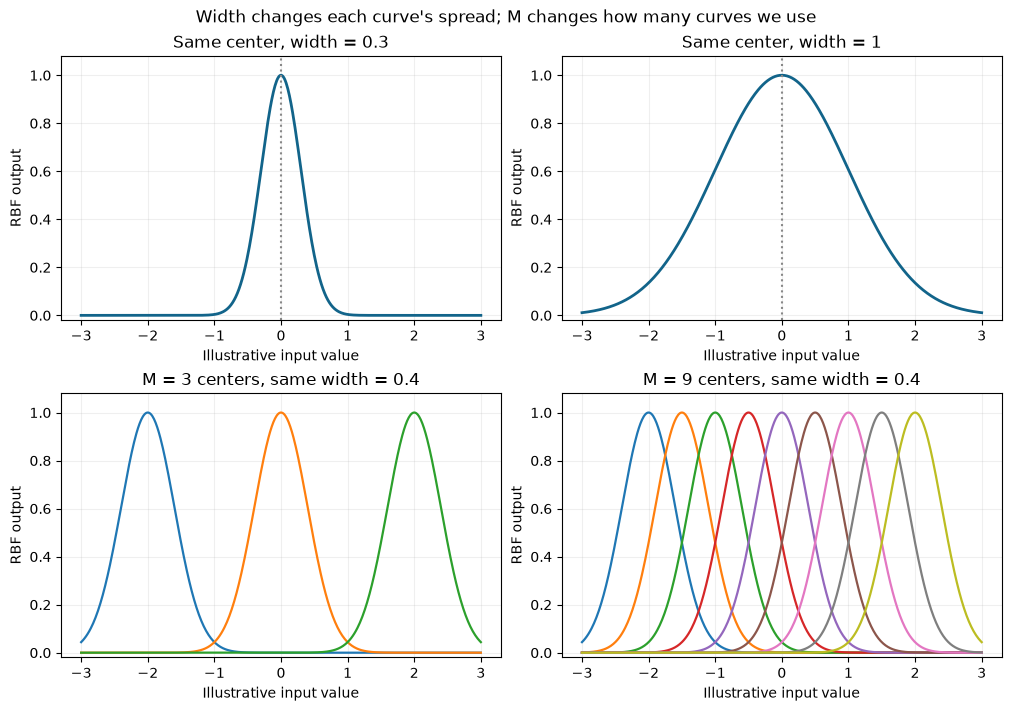

In [10]:
illustration_x = np.linspace(-3, 3, 500).reshape(-1, 1)
fig, axes = plt.subplots(2, 2, figsize=(10, 7), layout="constrained")
for ax, width in zip(axes[0], (0.3, 1.0)):
    response = gaussian_basis(illustration_x, np.array([[0.0]]), width)
    ax.plot(illustration_x[:, 0], response[:, 0], color="#12648a", linewidth=2)
    ax.axvline(0, color="#888888", linestyle=":")
    ax.set_title(f"Same center, width = {width:g}")
for ax, count in zip(axes[1], (3, 9)):
    illustration_centers = np.linspace(-2, 2, count).reshape(-1, 1)
    responses = gaussian_basis(illustration_x, illustration_centers, width=0.4)
    for j in range(count):
        ax.plot(illustration_x[:, 0], responses[:, j], linewidth=1.6)
    ax.set_title(f"M = {count} centers, same width = 0.4")
for ax in axes.flat:
    ax.set(xlabel="Illustrative input value", ylabel="RBF output", ylim=(-0.02, 1.08))
    ax.grid(alpha=0.2)
fig.suptitle("Width changes each curve's spread; M changes how many curves we use")
plt.show()


### 2.2 Design matrix


In [11]:
def design_matrix(x, centers, width):
    """Construct [1, phi_1, ..., phi_M] explicitly, including an intercept."""
    matrix = np.ones((len(x), len(centers) + 1))
    matrix[:, 1:] = gaussian_basis(x, centers, width)
    return matrix


### 2.3 Error functions


In [12]:
def sse(target, prediction):
    """Sum squared differences between actual counts and model predictions."""
    target, prediction = np.asarray(target), np.asarray(prediction)
    if target.ndim != 1 or prediction.shape != target.shape or len(target) == 0:
        raise ValueError("SSE requires matching nonempty one-dimensional vectors")
    residual = target - prediction
    return float(residual @ residual)

def rmse(target, prediction):
    """Convert mean squared error back to the target's units: rentals/day."""
    return math.sqrt(sse(target, prediction) / len(target))


### 2.4 Fit the weights


In [13]:
def fit_least_squares(matrix, target):
    """Least-squares solvers are explicitly permitted by the assignment brief."""
    weights, _, rank, singular_values = np.linalg.lstsq(matrix, target, rcond=None)
    condition = float(singular_values[0] / singular_values[-1]) if singular_values[-1] else float("inf")
    return weights, int(rank), condition


## 3. Fixed split, preprocessing, and center selection

Seed 42 creates **584 training / 147 test observations** (approximately 80/20).
Seed 43 divides only the training partition into **467 inner fitting / 117
validation observations**. The inner fitting partition has its own scaler and
centers. We choose the width from validation RMSE before looking at test errors,
then refit each candidate on the full outer training partition.

The split, 64 centers, and center-selection seed are fixed within each width
sweep. The random split measures interpolation within the observed two years;
correlated nearby days and the inclusion of both years in training mean this
is **not a future forecasting evaluation**. Such a claim needs a chronological
or blocked evaluation.


### 3.1 Create the outer training/test split


In [14]:
def shuffled_indices(n, seed):
    """A deterministic split using the standard library, independent of ML tools."""
    indices = list(range(n))
    random.Random(seed).shuffle(indices)
    return np.array(indices, dtype=int)


order = shuffled_indices(len(y), seed=42)
cut = int(0.8 * len(y))
train, test = order[:cut], order[cut:]
print(f"Training days: {len(train)}; test days: {len(test)}")


Training days: 584; test days: 147


### 3.2 Reserve training-only validation data

Select width on training-only validation data to avoid tuning on test errors.


In [15]:
inner_order = shuffled_indices(len(train), seed=43)
inner_cut = int(0.8 * len(train))
inner_fit = train[inner_order[:inner_cut]]
validation = train[inner_order[inner_cut:]]
print(f"Inner fitting days: {len(inner_fit)}; validation days: {len(validation)}")


Inner fitting days: 467; validation days: 117


### 3.3 Standardize using fitting-data statistics

Fit scaling statistics on training rows only. Standardize continuous inputs;
leave binary and category indicators unchanged.


In [16]:
def fit_scaler(x):
    """Compute population means/scales of continuous inputs using training rows only."""
    means = np.zeros(x.shape[1])
    scales = np.ones(x.shape[1])
    for j in range(len(CONTINUOUS)):
        means[j] = sum(float(value) for value in x[:, j]) / len(x)
        variance = sum((float(value) - means[j]) ** 2 for value in x[:, j]) / len(x)
        scales[j] = math.sqrt(variance) if variance > 0 else 1.0
    return means, scales

def transform(x, means, scales):
    """Apply previously fitted statistics; never recompute them on test data."""
    return (x - means) / scales


In [17]:
# Outer models: learn scaling from all outer training days.
means, scales = fit_scaler(x[train])
z_train = transform(x[train], means, scales)
z_test = transform(x[test], means, scales)

# Validation models: learn scaling from inner fitting days only.
inner_means, inner_scales = fit_scaler(x[inner_fit])
z_fit = transform(x[inner_fit], inner_means, inner_scales)
z_validation = transform(x[validation], inner_means, inner_scales)


### 3.4 Select RBF centers

Sample 64 centers from fitting data and hold them fixed across the width sweep.


In [18]:
def choose_centers(n, count=64, seed=44):
    """Choose center row positions from fitting data without using targets."""
    return shuffled_indices(n, seed)[:min(count, n)]


center_positions = choose_centers(len(train))
centers = z_train[center_positions]
inner_centers = z_fit[choose_centers(len(inner_fit))]
print(f"Centers: {len(centers)}; design-matrix columns including intercept: {len(centers) + 1}")


Centers: 64; design-matrix columns including intercept: 65


## 4. Hyperparameter study

First hold M = 64 fixed and test widths 0.5, 0.75, 1, 1.5, 2, 3, 5, 8, and 12.
First select a width using the training-only validation partition. Then fit on
all outer training examples and calculate **training and test RMSE separately**
at every width. Then vary the number of centers at fixed width, followed by
a full grid evaluating all 54 pairs.


In [19]:
WIDTHS = (0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0, 8.0, 12.0)

# Width selection is finished before computing any test errors.
validation_scores = []
for width in WIDTHS:
    weights, _, _ = fit_least_squares(design_matrix(z_fit, inner_centers, width), y[inner_fit])
    score = rmse(y[validation], design_matrix(z_validation, inner_centers, width) @ weights)
    validation_scores.append(score)
selected_width = WIDTHS[min(range(len(WIDTHS)), key=lambda i: validation_scores[i])]

print('Validation-selected width:', selected_width)


Validation-selected width: 2.0


### 4.1 Refit and evaluate each width


In [20]:
results, selected_weights, selected_prediction = [], None, None
for width, validation_score in zip(WIDTHS, validation_scores):
    matrix = design_matrix(z_train, centers, width)
    weights, rank, condition = fit_least_squares(matrix, y[train])
    train_prediction = matrix @ weights
    test_prediction = design_matrix(z_test, centers, width) @ weights
    results.append(dict(width=width, train_rmse=rmse(y[train], train_prediction),
                        test_rmse=rmse(y[test], test_prediction), validation_rmse=validation_score,
                        rank=rank, condition_number=condition))
    if width == selected_width:
        selected_weights, selected_prediction = weights, test_prediction


results_df = pd.DataFrame(results)
display(results_df[["width", "train_rmse", "test_rmse", "validation_rmse"]].round(2))


,width,train_rmse,test_rmse,validation_rmse
0,0.50,1775.11,1812.08,1823.30
1,0.75,1497.68,1503.04,1522.34
2,1.00,1086.57,1081.16,1098.20
3,1.50,705.51,764.77,770.16
4,2.00,620.31,697.09,734.80
5,3.00,602.50,679.55,750.22
6,5.00,610.17,689.77,769.83
7,8.00,618.48,703.71,786.44
8,12.00,624.12,711.83,795.23


### 4.2 Compare the RMSE curves


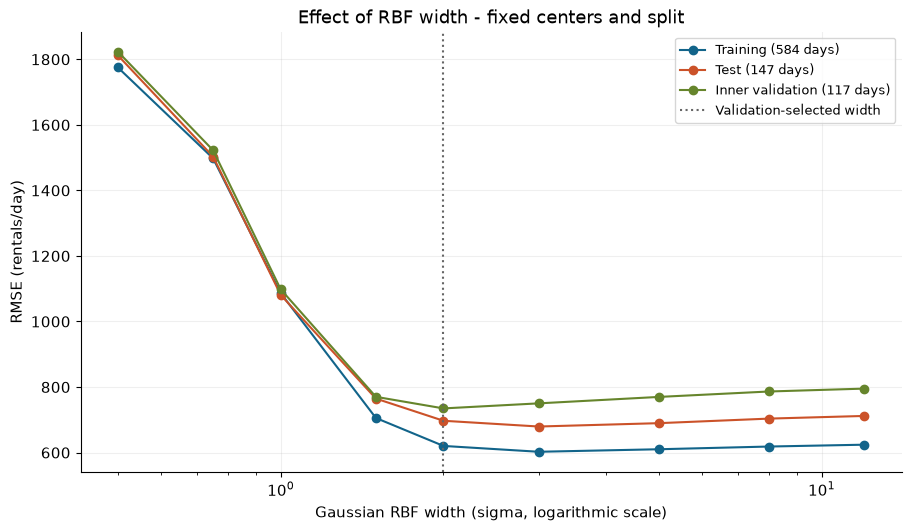

In [21]:
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(9, 5.2), layout="constrained")
for key, label, color in [("train_rmse", f"Training ({len(train)} days)", "#12648a"),
                          ("test_rmse", f"Test ({len(test)} days)", "#cb5229"),
                          ("validation_rmse", f"Inner validation ({len(validation)} days)", "#66852c")]:
    ax.plot(WIDTHS, [r[key] for r in results], "o-", label=label, color=color)
ax.axvline(selected_width, linestyle=":", color="#666666", label="Validation-selected width")
ax.set(xscale="log", xlabel="Gaussian RBF width (sigma, logarithmic scale)",
       ylabel="RMSE (rentals/day)", title="Effect of RBF width - fixed centers and split")
ax.grid(alpha=0.2)
ax.legend(fontsize=9)
plt.show()


### 4.3 Width-study model and constant baseline

Use the training-mean predictor as a baseline for interpreting the model's RMSE.


**Validation-selected width: 2**  
Training RMSE: **620.31**; test RMSE: **697.09 rentals/day**.  
Training-mean baseline: training RMSE 1942.34, test RMSE 1910.15.  
Test RMSE reduction relative to this baseline: **63.5%**.  
Descriptive minimum test RMSE: 679.55 at width 3; we retain the validation-selected width.

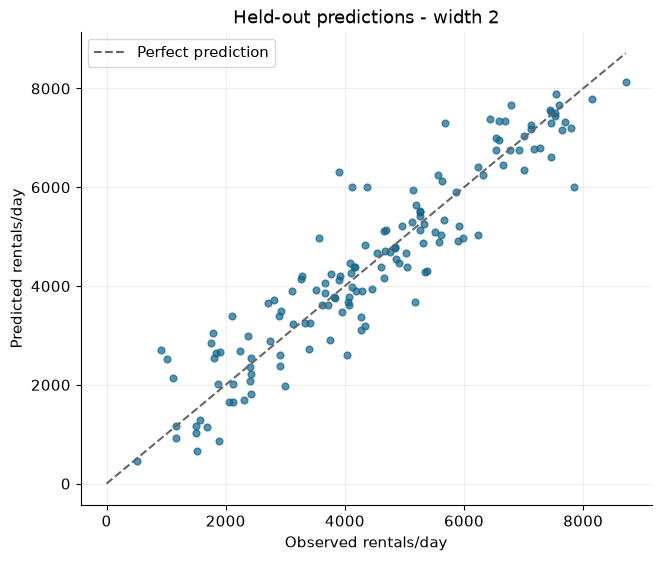

In [22]:
train_mean = sum(float(value) for value in y[train]) / len(train)
baseline_train = rmse(y[train], np.full(len(train), train_mean))
baseline_test = rmse(y[test], np.full(len(test), train_mean))
chosen = next(r for r in results if r["width"] == selected_width)
lowest_test = min(results, key=lambda r: r["test_rmse"])
improvement = 100 * (1 - chosen["test_rmse"] / baseline_test)
display(Markdown(
    f"**Validation-selected width: {selected_width:g}**  \n"
    f"Training RMSE: **{chosen['train_rmse']:.2f}**; test RMSE: **{chosen['test_rmse']:.2f} rentals/day**.  \n"
    f"Training-mean baseline: training RMSE {baseline_train:.2f}, test RMSE {baseline_test:.2f}.  \n"
    f"Test RMSE reduction relative to this baseline: **{improvement:.1f}%**.  \n"
    f"Descriptive minimum test RMSE: {lowest_test['test_rmse']:.2f} at width {lowest_test['width']:g}; "
    "we retain the validation-selected width."
))
fig, ax = plt.subplots(figsize=(6.5, 5.5), layout="constrained")
ax.scatter(y[test], selected_prediction, alpha=0.7, s=24, color="#12648a")
low = min(0, float(min(selected_prediction)))
high = max(float(max(y[test])), float(max(selected_prediction)))
ax.plot([low, high], [low, high], "--", color="#666666", label="Perfect prediction")
ax.set(xlabel="Observed rentals/day", ylabel="Predicted rentals/day",
       title=f"Held-out predictions - width {selected_width:g}")
ax.grid(alpha=0.2)
ax.legend()
plt.show()


### 4.4 Study the number of centers

Fix width at the validation-selected value and test **M = 8, 16, 32, 64, 128, 256**.
Use the same split and scaling. Each larger center set extends the same shuffled
prefix, so the basis sets are nested at this fixed width. Training SSE should
therefore not increase, apart from numerical effects. All fitting systems still
have more observations than coefficients.


In [23]:
def fit_rbf_model(inputs, targets, count, width):
    """Fit an RBF model using a reproducible prefix of fitting-data centers."""
    if count < 1 or count + 1 >= len(inputs):
        raise ValueError("Use a positive center count with fewer weights than fitting rows")
    centers = inputs[choose_centers(len(inputs), count=count)]
    matrix = design_matrix(inputs, centers, width)
    weights, rank, condition = fit_least_squares(matrix, targets)
    return centers, weights, rank, condition


In [24]:
CENTER_COUNTS = (8, 16, 32, 64, 128, 256)

# Study the number of centers at the validation-selected width.
count_validation_scores = []
for count in CENTER_COUNTS:
    count_centers, count_weights, _, _ = fit_rbf_model(z_fit, y[inner_fit], count, selected_width)
    prediction = design_matrix(z_validation, count_centers, selected_width) @ count_weights
    count_validation_scores.append(rmse(y[validation], prediction))
selected_count = CENTER_COUNTS[min(range(len(CENTER_COUNTS)), key=lambda i: count_validation_scores[i])]

count_results = []
for count, validation_score in zip(CENTER_COUNTS, count_validation_scores):
    count_centers, count_weights, rank, condition = fit_rbf_model(z_train, y[train], count, selected_width)
    count_train_prediction = design_matrix(z_train, count_centers, selected_width) @ count_weights
    count_test_prediction = design_matrix(z_test, count_centers, selected_width) @ count_weights
    count_results.append(dict(center_count=count, width=selected_width,
                              train_rmse=rmse(y[train], count_train_prediction),
                              test_rmse=rmse(y[test], count_test_prediction),
                              validation_rmse=validation_score, rank=rank, condition_number=condition))


count_results_df = pd.DataFrame(count_results)
display(count_results_df[["center_count", "train_rmse", "test_rmse", "validation_rmse"]].round(2))
count_chosen = next(r for r in count_results if r["center_count"] == selected_count)
display(Markdown(
    f"**Validation-selected M: {selected_count}, width: {selected_width:g}.** "
    f"Training RMSE: **{count_chosen['train_rmse']:.2f}**; "
    f"test RMSE: **{count_chosen['test_rmse']:.2f} rentals/day**."
))


,center_count,train_rmse,test_rmse,validation_rmse
0,8,1259.38,1343.45,1653.84
1,16,1037.97,1037.76,1090.46
2,32,746.08,798.08,829.65
3,64,620.31,697.09,734.80
4,128,514.28,699.28,718.93
5,256,400.00,754.98,722.04


**Validation-selected M: 128, width: 2.** Training RMSE: **514.28**; test RMSE: **699.28 rentals/day**.

### 4.5 RMSE versus number of centers


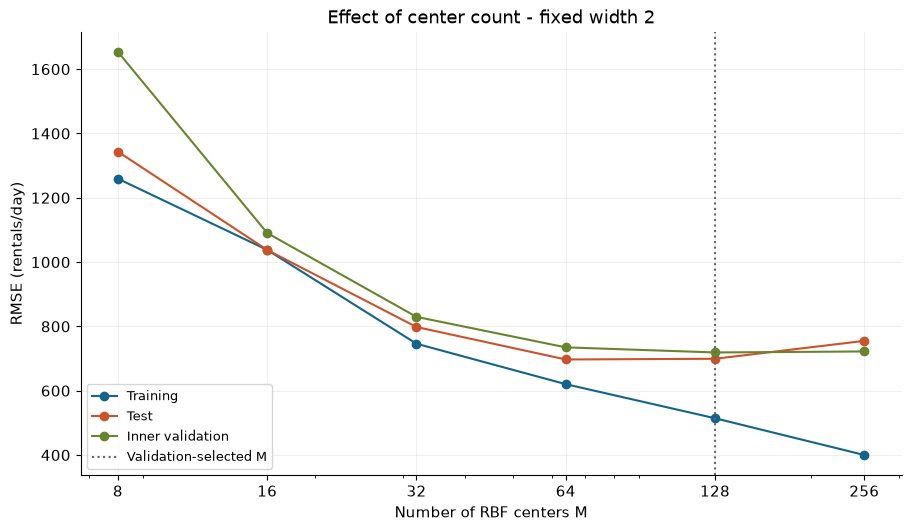

In [25]:
fig, ax = plt.subplots(figsize=(9, 5.2), layout="constrained")
for key, label, color in [("train_rmse", "Training", "#12648a"),
                          ("test_rmse", "Test", "#cb5229"),
                          ("validation_rmse", "Inner validation", "#66852c")]:
    ax.plot(CENTER_COUNTS, [r[key] for r in count_results], "o-", label=label, color=color)
ax.axvline(selected_count, linestyle=":", color="#666666", label="Validation-selected M")
ax.set(xscale="log", xlabel="Number of RBF centers M", ylabel="RMSE (rentals/day)",
       title=f"Effect of center count - fixed width {selected_width:g}")
ax.set_xticks(CENTER_COUNTS, labels=[str(count) for count in CENTER_COUNTS])
ax.grid(alpha=0.2)
ax.legend(fontsize=9)
plt.show()


### 4.6 Full grid: choose width and center count jointly

Evaluate **6 center counts × 9 widths = 54 combinations**. The same splits,
scaling, and shuffled center prefixes are used for every pair. Select the pair
with the lowest inner validation RMSE before calculating test-grid errors.


In [26]:
# Joint hyperparameter search: select the pair before evaluating test errors.
grid_validation_results = []
for count in CENTER_COUNTS:
    for width in WIDTHS:
        grid_centers, grid_weights, _, _ = fit_rbf_model(z_fit, y[inner_fit], count, width)
        prediction = design_matrix(z_validation, grid_centers, width) @ grid_weights
        grid_validation_results.append(dict(center_count=count, width=width,
                                            validation_rmse=rmse(y[validation], prediction)))
grid_best_validation = min(grid_validation_results, key=lambda row: row["validation_rmse"])
grid_selected_count = grid_best_validation["center_count"]
grid_selected_width = grid_best_validation["width"]


print('Validation-selected pair:', grid_best_validation)


Validation-selected pair: {'center_count': 256, 'width': 1.5, 'validation_rmse': 700.7816637594685}


In [27]:
grid_results = []
for setting in grid_validation_results:
    count, width = setting["center_count"], setting["width"]
    grid_centers, grid_weights, rank, condition = fit_rbf_model(z_train, y[train], count, width)
    grid_train_prediction = design_matrix(z_train, grid_centers, width) @ grid_weights
    grid_test_prediction = design_matrix(z_test, grid_centers, width) @ grid_weights
    grid_results.append(dict(**setting, train_rmse=rmse(y[train], grid_train_prediction),
                             test_rmse=rmse(y[test], grid_test_prediction),
                             rank=rank, condition_number=condition))
    if count == grid_selected_count and width == grid_selected_width:
        grid_selected_centers = grid_centers
        grid_selected_weights = grid_weights
        grid_selected_prediction = grid_test_prediction


grid_results_df = pd.DataFrame(grid_results)
validation_grid = np.array([r["validation_rmse"] for r in grid_results]).reshape(len(CENTER_COUNTS), len(WIDTHS))
display(Markdown("**Validation RMSE: rows = center count, columns = width**"))
display(pd.DataFrame(validation_grid, index=CENTER_COUNTS, columns=WIDTHS).round(2))
grid_chosen = next(r for r in grid_results if r["center_count"] == grid_selected_count
                   and r["width"] == grid_selected_width)
display(Markdown(
    f"**Joint selection: M = {grid_selected_count}, width = {grid_selected_width:g}.** "
    f"Train RMSE: **{grid_chosen['train_rmse']:.2f}**; "
    f"validation RMSE: **{grid_chosen['validation_rmse']:.2f}**; "
    f"test RMSE: **{grid_chosen['test_rmse']:.2f} rentals/day**."
))


**Validation RMSE: rows = center count, columns = width**

,0.50,0.75,1.00,1.50,2.00,3.00,5.00,8.00,12.00
8,1906.53,1900.84,1847.47,1744.54,1653.84,1558.07,1509.57,1495.16,1490.48
16,1899.82,1838.36,1623.99,1257.13,1090.46,943.23,885.24,876.55,877.11
32,1859.78,1631.50,1255.05,932.00,829.65,796.78,812.74,823.20,827.14
64,1823.30,1522.34,1098.20,770.16,734.80,750.22,769.83,786.44,795.23
128,1747.19,1288.67,896.64,729.62,718.93,744.93,771.33,780.81,784.80
256,1633.68,1145.84,827.89,700.78,722.04,761.91,819.89,851.96,865.95


**Joint selection: M = 256, width = 1.5.** Train RMSE: **429.42**; validation RMSE: **700.78**; test RMSE: **731.94 rentals/day**.

### 4.7 Training, validation, and test heatmaps

Each cell represents one fitted setting. All panels share the same color scale;
orange boxes mark the validation-selected pair on all three panels.


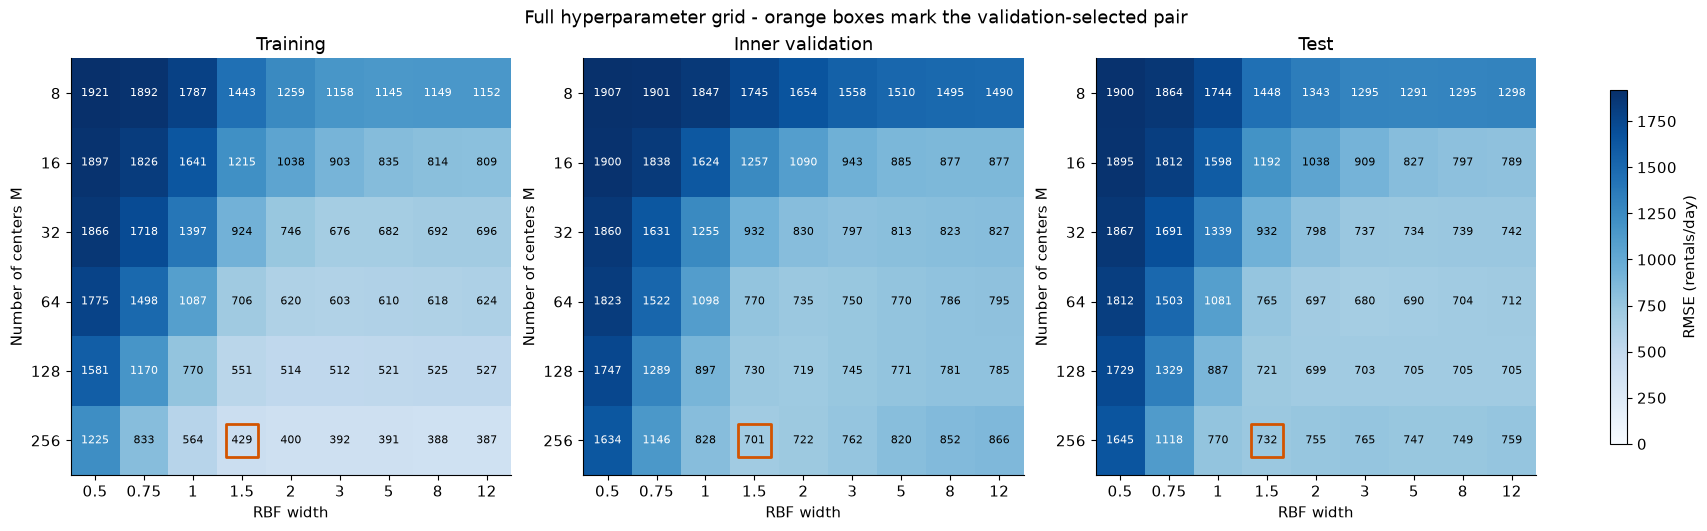

In [28]:
def plot_hyperparameter_grid(results, selected_count, selected_width):
    """Show train, validation, and test RMSE on the same color scale."""
    import matplotlib.pyplot as plt

    metrics = [("train_rmse", "Training"), ("validation_rmse", "Inner validation"),
               ("test_rmse", "Test")]
    maximum = max(row[key] for row in results for key, _ in metrics)
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), layout="constrained")
    for ax, (key, title) in zip(axes, metrics):
        values = np.array([row[key] for row in results]).reshape(len(CENTER_COUNTS), len(WIDTHS))
        heatmap = ax.imshow(values, aspect="auto", cmap="Blues", vmin=0, vmax=maximum)
        ax.set_xticks(range(len(WIDTHS)), labels=[f"{width:g}" for width in WIDTHS])
        ax.set_yticks(range(len(CENTER_COUNTS)), labels=[str(count) for count in CENTER_COUNTS])
        ax.set(xlabel="RBF width", ylabel="Number of centers M", title=title)
        for i in range(len(CENTER_COUNTS)):
            for j in range(len(WIDTHS)):
                ax.text(j, i, f"{values[i, j]:.0f}", ha="center", va="center", fontsize=8,
                        color="white" if values[i, j] > maximum * 0.55 else "black")
        ax.scatter(WIDTHS.index(selected_width), CENTER_COUNTS.index(selected_count),
                   marker="s", s=550, facecolors="none", edgecolors="#d35400", linewidths=2)
    fig.colorbar(heatmap, ax=axes, label="RMSE (rentals/day)", shrink=0.85)
    fig.suptitle("Full hyperparameter grid - orange boxes mark the validation-selected pair")
    return fig

fig = plot_hyperparameter_grid(grid_results, grid_selected_count, grid_selected_width)
plt.show()


### 4.8 The selected model's RBF features

With M = 256, each day becomes 256 RBF values. The heatmap below shows 30 test
days against all centers: brighter cells mean greater similarity to that center.
This is the actual basis matrix, before adding the intercept or multiplying by
learned weights. Center order follows the seeded sample, not a spatial ordering.

The model has 257 weights for 584 outer training days (and 467 inner fitting
days during validation). This is a relatively flexible model. Its selection at
the largest tested M does not prove that 256 centers are necessary or globally optimal.


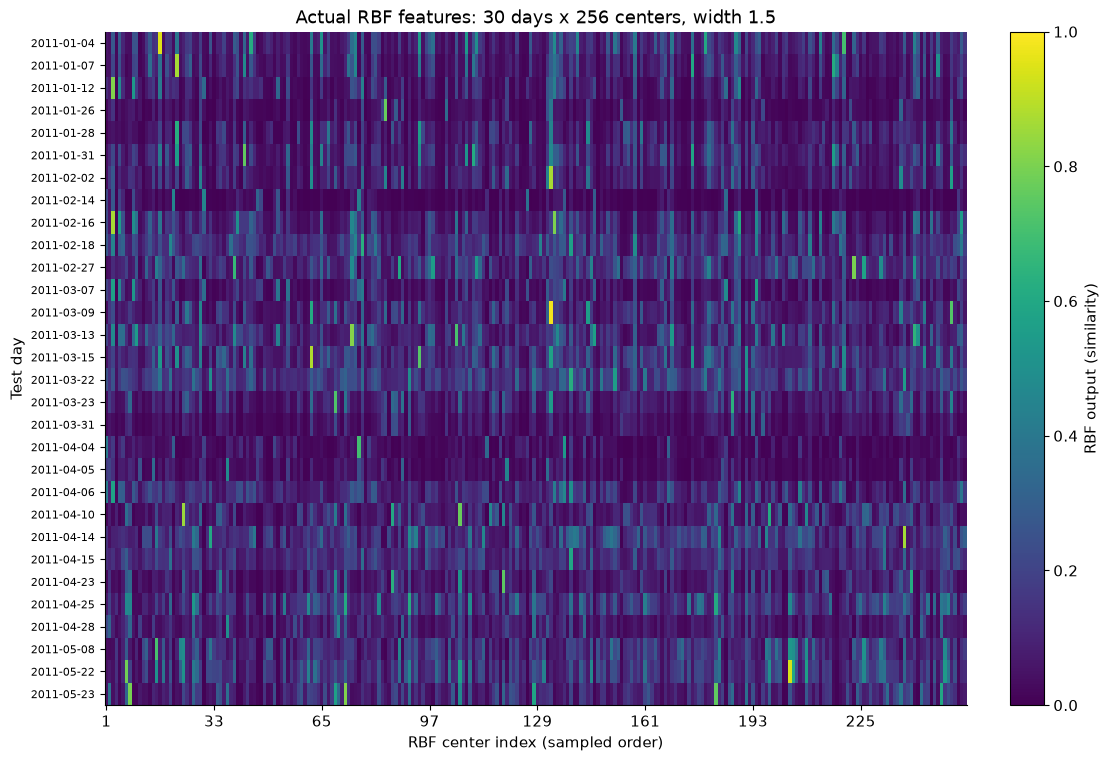

In [29]:
view_positions = np.argsort(test)[:30]
displayed_rows = test[view_positions]
activations = gaussian_basis(z_test[view_positions], grid_selected_centers, grid_selected_width)
fig, ax = plt.subplots(figsize=(11, 7.5), layout="constrained")
image = ax.imshow(activations, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_yticks(range(len(displayed_rows)), labels=[df["date"].iloc[int(i)] for i in displayed_rows], fontsize=8)
ticks = list(range(0, grid_selected_count, 32))
ax.set_xticks(ticks, labels=[str(i + 1) for i in ticks])
ax.set(xlabel="RBF center index (sampled order)", ylabel="Test day",
       title=f"Actual RBF features: {len(displayed_rows)} days x {grid_selected_count} centers, width {grid_selected_width:g}")
fig.colorbar(image, ax=ax, label="RBF output (similarity)")
plt.show()


## 5. Discussion and conclusions

**Width study (M = 64).**

Validation selected **width 2.0**, giving training RMSE **620.31** and test RMSE
**697.09 rentals/day**. The training-mean baseline has test RMSE **1910.15**,
so the selected model reduces test RMSE by **63.5%**.

Narrow RBFs (width 0.5) give high training and test errors because they respond
only near their centers. Intermediate widths represent the data better. Very
broad RBFs become similar to one another, and test error rises slightly.
Training error need not decrease monotonically because changing width does not
create a nested sequence of models.

Width 3 has the lowest test RMSE in this sweep (**679.55**). We retain width 2,
chosen using training-only validation, to avoid tuning on the test set.

**Center-count study (width = 2).** Training RMSE falls from **1259.38** at
M = 8 to **400.00** at M = 256. Validation selects **M = 128**, giving training
RMSE **514.28**, validation RMSE **718.93**, and test RMSE **699.28**.
At M = 256 the lower training error accompanies higher validation and test errors
(**722.04** and **754.98**), consistent with overfitting as capacity increases.

M = 64 has slightly lower test RMSE than M = 128 at this width; the selected count
remains 128 because selection uses validation. These are two sequential sweeps:
width is selected at M = 64, then M is selected at that width. Width is not
re-tuned separately for each center count.

**Full grid.** Joint validation selects **M = 256, width = 1.5**, with validation
RMSE **700.78**. After refitting on all outer training rows, train/test RMSE are
**429.42 / 731.94**. This is the final selection from the tested grid. Its lower
validation error does not translate into a lower test error than the sequential
choice: searching more candidates does not guarantee better generalization on
a single split. The full grid reveals how the preferred width changes with M.

The minimum descriptive test RMSE over the grid is **679.55** at M = 64 and
width = 3. We report that value but do not use it to choose the model.

These results apply to this fixed random split. Nearby days can be correlated;
a chronological split would be needed to evaluate future forecasting accuracy.


## 6. References

- Instructor's *Linear Regression - Programming Assignment - Part 1* brief.
- Fanaee-T, H. (2013). *Bike Sharing*. UCI Machine Learning Repository.
  [Dataset DOI](https://doi.org/10.24432/C5W894), [UCI record](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset).
- Fanaee-T, H. and Gama, J. (2013). *Event labeling combining ensemble detectors
  and background knowledge*. [Paper DOI](https://doi.org/10.1007/s13748-013-0040-3).
- Original dataset archive's `Readme.txt`, preserved in the course workspace and submission ZIP.
- Bishop, C. M. (2006). *Pattern Recognition and Machine Learning*, Chapter 3.
- [NumPy least-squares solver documentation](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html).
